# NFL Impact Detection · Dataset Exploration
## 1. Introduction


In [18]:
from pathlib import Path
import sys
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from IPython.display import display, Markdown

## 2. Dataset Overview
The first three CSVs are required for the full analysis. The submission file is optional here: absence is reported, and its contents are never fabricated. Identifiers are preserved; every count below is calculated from the loaded files.


#### Image Labels

In [52]:
image_lables = pd.read_csv(r"C:\Users\deanr\Computer-Vision-NFL\data\image_labels.csv")
print(f"Shape: {image_lables.shape} \n")
print(f"Missing Values: \n{image_lables.isna().sum()} \n")
image_lables.head(5)

Shape: (193736, 6) 

Missing Values: 
image     0
label     0
left      0
width     0
top       0
height    0
dtype: int64 



,image,label,left,width,top,height
0,57503_000116_Endzone_frame443.jpg,Helmet,1099,16,456,15
1,57503_000116_Endzone_frame443.jpg,Helmet,1117,15,478,16
2,57503_000116_Endzone_frame443.jpg,Helmet,828,16,511,15
3,57503_000116_Endzone_frame443.jpg,Helmet,746,16,519,16
4,57503_000116_Endzone_frame443.jpg,Helmet,678,17,554,17


In [ ]:
image_lables['label'].unique()
# 5 different label types

<StringArray>
[          'Helmet',   'Helmet-Blurred', 'Helmet-Difficult',
  'Helmet-Sideline',   'Helmet-Partial']
Length: 5, dtype: str

In [47]:
image_lables.describe()

,left,width,top,height
count,193736.000000,193736.000000,193736.000000,193736.000000
mean,631.000877,17.939547,303.968132,18.987617
std,274.899250,8.647087,140.436898,9.315455
min,0.000000,3.000000,0.000000,3.000000
25%,437.000000,11.000000,221.000000,12.000000
50%,630.000000,16.000000,298.000000,17.000000
75%,826.000000,24.000000,374.000000,25.000000
max,1277.000000,144.000000,717.000000,107.000000


#### Test Player Tracking

In [75]:
player_track = pd.read_csv(r"C:\Users\deanr\Computer-Vision-NFL\data\test_player_tracking.csv")
print(f"Shape: {player_track.shape} \n")
print(f"Missing Values: \n{player_track.isna().sum()} \n")
# Lots of missing events (makes sense bc its like play start etc)
player_track.head(5)

Shape: (19269, 12) 

Missing Values: 
gameKey        0
playID         0
player         0
time           0
x              0
y              0
s              0
a              0
dis            0
o              0
dir            0
event      18785
dtype: int64 



,gameKey,playID,player,time,x,y,s,a,dis,o,dir,event
0,57906,718,H55,2019-09-08T17:29:28.700Z,11.92,30.08,2.15,0.80,0.22,112.10,89.85,huddle_start_offense
1,57906,718,H55,2019-09-08T17:29:28.799Z,12.14,30.07,2.07,1.06,0.21,108.40,91.43,NaN
2,57906,718,H55,2019-09-08T17:29:28.900Z,12.34,30.06,1.97,1.22,0.20,104.14,92.42,NaN
3,57906,718,H55,2019-09-08T17:29:29.000Z,12.53,30.05,1.85,1.30,0.19,100.61,93.22,NaN
4,57906,718,H55,2019-09-08T17:29:29.099Z,12.71,30.04,1.75,1.30,0.18,97.01,93.86,NaN


In [76]:
print(f"Event Types: {player_track['event'].unique()} \n")
print(player_track['event'].value_counts())

Event Types: <StringArray>
['huddle_start_offense',                    nan, 'huddle_break_offense',
             'line_set',            'ball_snap',              'handoff',
               'tackle',         'penalty_flag',        'out_of_bounds',
        'first_contact']
Length: 10, dtype: str 

event
line_set                110
huddle_break_offense     66
ball_snap                66
handoff                  66
huddle_start_offense     44
tackle                   44
penalty_flag             44
out_of_bounds            22
first_contact            22
Name: count, dtype: int64


In [77]:
print(f"Players: {player_track['player'].unique()} \n")
# 58 players
print(f"Play ID: {player_track['playID'].unique()}")
# 3 different play IDs

Players: <StringArray>
['H55', 'H70', 'H68', 'H67', 'H26', 'H85', 'H81', 'H87', 'H72', 'H14', 'H47',
 'V55', 'V57', 'V23', 'V21', 'V98', 'V93', 'V27', 'V58', 'V49', 'V39', 'V91',
 'H97', 'H36', 'H23', 'H21', 'H52', 'H99', 'H59', 'H91', 'H94', 'H30', 'H93',
 'V65', 'V68', 'V60', 'V77', 'V83', 'V12', 'V74', 'V17', 'V75', 'V15', 'H25',
 'H58', 'H54', 'H90', 'H37', 'H42', 'V76', 'V13', 'V25', 'V86', 'V66', 'V81',
 'V16', 'V61', 'V78']
Length: 58, dtype: str 

Play ID: [ 718  109 2798]


#### Train Labels

In [84]:
train_labels = pd.read_csv(r"C:\Users\deanr\Computer-Vision-NFL\data\train_labels.csv")
print(f"Shape: {train_labels.shape} \n")
print(f"Missing Values: \n{train_labels.isna().sum()} \n")
train_labels.head(5)

Shape: (983885, 14) 

Missing Values: 
gameKey            0
playID             0
view               0
video              0
frame              0
label              0
left               0
width              0
top                0
height             0
impact        981594
impactType    981594
confidence    981594
visibility    981594
dtype: int64 



,gameKey,playID,view,video,frame,label,left,width,top,height,impact,impactType,confidence,visibility
0,57583,82,Endzone,57583_000082_Endzone.mp4,1,H30,629,19,40,24,NaN,NaN,NaN,NaN
1,57583,82,Endzone,57583_000082_Endzone.mp4,1,V72,443,22,344,16,NaN,NaN,NaN,NaN
2,57583,82,Endzone,57583_000082_Endzone.mp4,1,V86,871,21,359,17,NaN,NaN,NaN,NaN
3,57583,82,Endzone,57583_000082_Endzone.mp4,1,V74,771,19,345,15,NaN,NaN,NaN,NaN
4,57583,82,Endzone,57583_000082_Endzone.mp4,1,V34,549,26,461,20,NaN,NaN,NaN,NaN


In [91]:
train_labels['label'].unique()

<StringArray>
['H30', 'V72', 'V86', 'V74', 'V34', 'H97', 'H99', 'V73', 'V87', 'H96',
 ...
  'V9', 'H45', 'H92',  'V7', 'H66',  'H5', 'V50', 'H16',  'H7', 'H61']
Length: 196, dtype: str

In [92]:
train_labels['impact'].value_counts()

impact
1.0    2291
Name: count, dtype: int64

In [93]:
train_labels['impactType'].value_counts()

impactType
Helmet      1553
Shoulder     346
Body         332
Ground        56
Hand           2
shoulder       2
Name: count, dtype: int64

In [94]:
train_labels['visibility'].value_counts()

visibility
2.0    815
3.0    768
1.0    545
0.0    163
Name: count, dtype: int64

#### Train Player Tracking

In [97]:
train_tracking = pd.read_csv(r"C:\Users\deanr\Computer-Vision-NFL\data\train_player_tracking.csv")
print(f"Shape: {train_tracking.shape} \n")
print(f"Missing Values: \n{train_tracking.isna().sum()} \n")
train_tracking.head(5)

Shape: (333811, 12) 

Missing Values: 
gameKey         0
playID          0
player          0
time            0
x               0
y               0
s               0
a               0
dis             0
o               0
dir             0
event      323691
dtype: int64 



,gameKey,playID,player,time,x,y,s,a,dis,o,dir,event
0,57583,82,H97,2018-09-14T00:23:45.500Z,38.89,28.06,0.0,0.0,0.0,261.28,222.79,NaN
1,57583,82,H97,2018-09-14T00:23:45.599Z,38.89,28.06,0.0,0.0,0.0,261.28,221.93,NaN
2,57583,82,H97,2018-09-14T00:23:45.700Z,38.89,28.06,0.0,0.0,0.0,261.28,221.21,NaN
3,57583,82,H97,2018-09-14T00:23:45.799Z,38.88,28.05,0.0,0.0,0.0,261.28,220.07,NaN
4,57583,82,H97,2018-09-14T00:23:45.900Z,38.88,28.05,0.0,0.0,0.0,261.28,220.31,NaN


In [104]:
train_tracking['playID'].unique()

array([  82,  336, 2674,  540, 1934, 4152, 2918,  923, 2686,  658, 1242,
       3572, 3316, 2206, 3470, 2630, 1985, 2546, 1264,  933, 4244,  252,
        600, 3374, 1741, 2026, 3085, 3413,  781, 2792, 2839, 1367, 2404,
        718, 3615, 1164,  147, 2492, 1325,  218, 3093,  301,  350,  475,
        109, 3691, 2181, 1306, 1254, 1612,   86, 1923,  423, 2819, 4022,
       1193, 2798, 3494,  352, 4362])

In [105]:
train_tracking['player'].unique()

<StringArray>
['H97', 'H96', 'H90', 'H27', 'H36', 'H99', 'H59', 'H22', 'H50', 'H56',
 ...
  'V9', 'H92', 'H45',  'V7',  'H5', 'H66', 'H16', 'V50',  'H7', 'H61']
Length: 194, dtype: str

## 4. Image Exploration
Filename matching is exact, including zero-padded frame strings. Media lookup is recursive and resolves the current subdirectory layout. Duplicate video basenames prefer the training copy, since mock test videos may reuse names.

Nine images are sampled across helmet-count ranks with seed 42 to cover sparse and crowded scenes. Green rectangles are helmet boxes. Aspect ratios are preserved.


In [101]:
image_index, duplicate_image_names = media_index(DATA, {".jpg", ".jpeg", ".png"})
video_index, duplicate_video_names = media_index(DATA, {".mp4"}, preferred_subdir="train")
image_dims = image_dimensions(image_labels.image.dropna().unique(), image_index)
video_meta = video_metadata(train_labels.video.dropna().unique(), video_index)

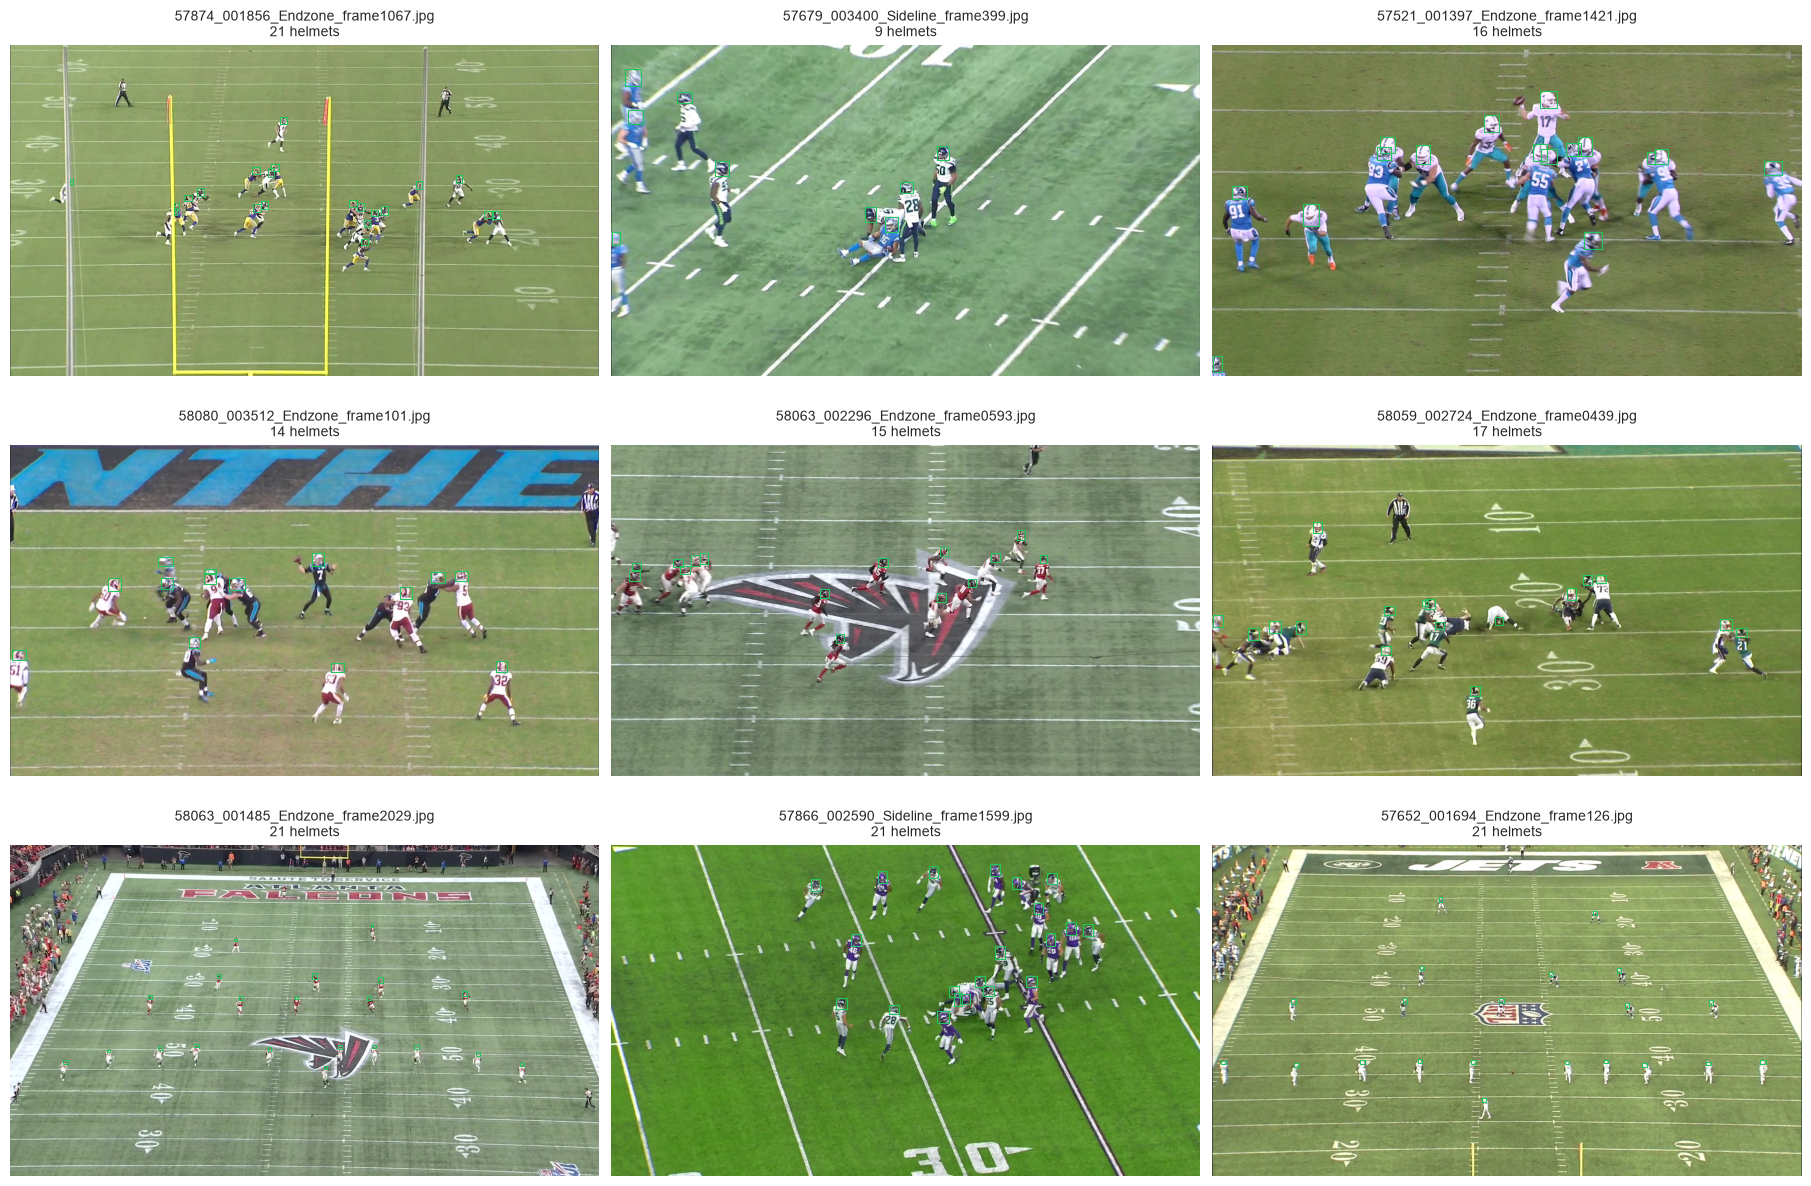

In [102]:
image_counts = image_labels.groupby("image").size()
helmet_counts = image_labels.loc[image_labels.label.eq("Helmet")].groupby("image").size().reindex(image_counts.index, fill_value=0)

available_images = helmet_counts.loc[helmet_counts.index.isin(
    image_dims.loc[image_dims.status.eq("available"), "image"])].sort_values()
sample_images = []
for group in np.array_split(available_images.index.to_numpy(), min(9, len(available_images)) or 1):
    if len(group):
        sample_images.append(str(rng.choice(group)))
if sample_images:
    fig, axes = plt.subplots(3, 3, figsize=(18, 12), layout="constrained")
    for name, ax in zip(sample_images, axes.flat):
        show_image(name, image_labels, image_index, ax=ax)
    for ax in axes.flat[len(sample_images):]:
        ax.axis("off")
    plt.show()

## 5. Helmet Bounding Box Analysis
Sizes are measured in pixels; area is width × height. Invalid geometry is reported before valid helmet boxes are used for distributions. Header dimensions allow bounds checks for every available labeled image without loading all images into memory.

Small helmets contain little visual detail, while scale changes and crowding can complicate detection. Size variation will inform future resizing and augmentation choices.


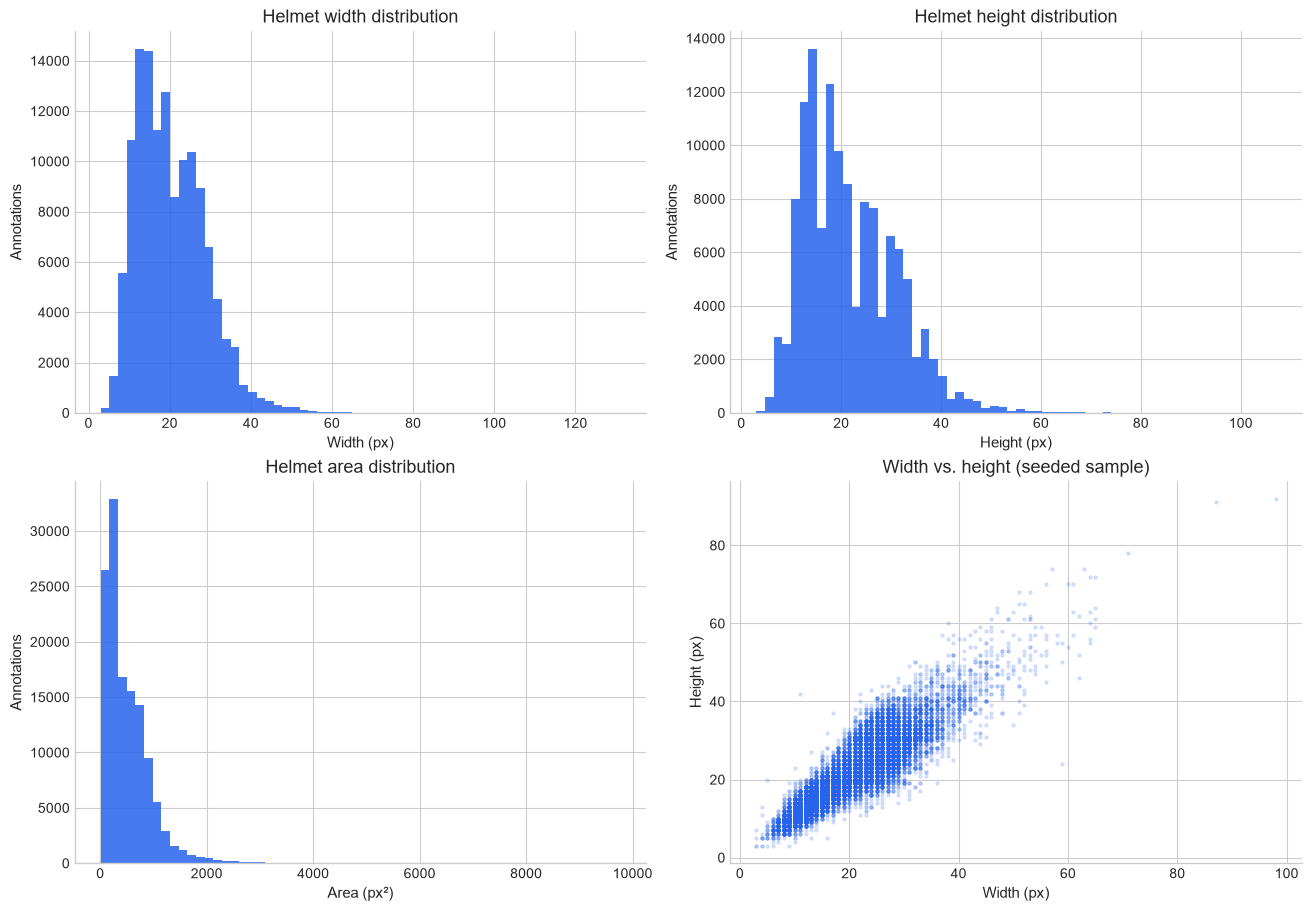

In [109]:
image_boxes = box_checks(image_labels, image_dims)
valid_helmets = image_boxes.loc[image_boxes.label.eq("Helmet") & ~image_boxes.invalid_box].copy()

fig, axes = plt.subplots(2, 2, figsize=(13, 9), layout="constrained")
for ax, column, unit in zip(axes.flat[:3], ["width", "height", "area"], ["px", "px", "px²"]):
    ax.hist(valid_helmets[column].dropna(), bins=60, color=BLUE, alpha=0.85)
    ax.set(title=f"Helmet {column} distribution", xlabel=f"{column.title()} ({unit})", ylabel="Annotations")
box_sample = valid_helmets.sample(min(15000, len(valid_helmets)), random_state=SEED)
axes[1, 1].scatter(box_sample.width, box_sample.height, s=5, alpha=0.15, color=BLUE)
axes[1, 1].set(title="Width vs. height (seeded sample)", xlabel="Width (px)", ylabel="Height (px)")
plt.show()


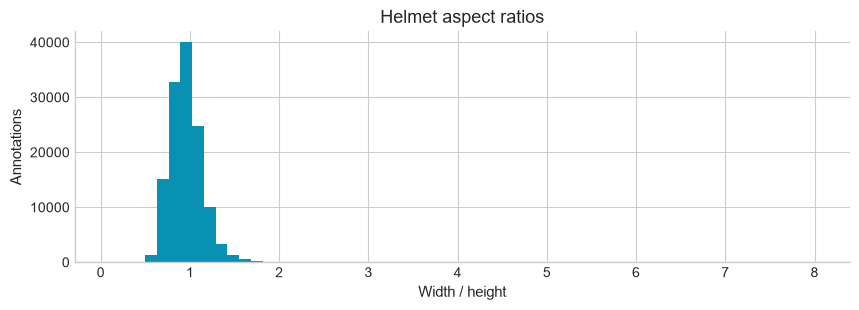

In [110]:
fig, ax = plt.subplots(figsize=(10, 3))
ax.hist(valid_helmets.aspect_ratio.dropna(), bins=60, color="#0891b2")
ax.set(title="Helmet aspect ratios", xlabel="Width / height", ylabel="Annotations")
plt.show()

## 6. Video and Frame Exploration
The dominant CSV convention is one-based: frame 1 maps to OpenCV position 0. We inspect zero/fractional/missing frames and compare labeled maxima with **measured** video lengths. Unexpected rows are reported rather than silently clamped or shifting every video.

Measured FPS comes from each MP4. Counts here are **labeled frames**, which may differ from decoded video frame counts. The examples let us visually check box placement. Red boxes indicate impact-positive rows; player labels come from the CSV.


In [113]:
frames_per_video = frame_counts.groupby(level="video").size().rename("Labeled frames")
views_per_play = train_labels.groupby(play_keys).view.agg(lambda values: set(values.dropna()))
both_views = views_per_play.map(lambda views: {"Sideline", "Endzone"}.issubset(views))
videos_per_view = train_labels[["video", "view"]].drop_duplicates().groupby("view").size()
frame_ranges = train_labels.groupby("video").frame.agg(["min", "max"]).reset_index()
video_coverage = video_meta.merge(frames_per_video.reset_index(), on="video", validate="one_to_one").merge(frame_ranges, on="video")


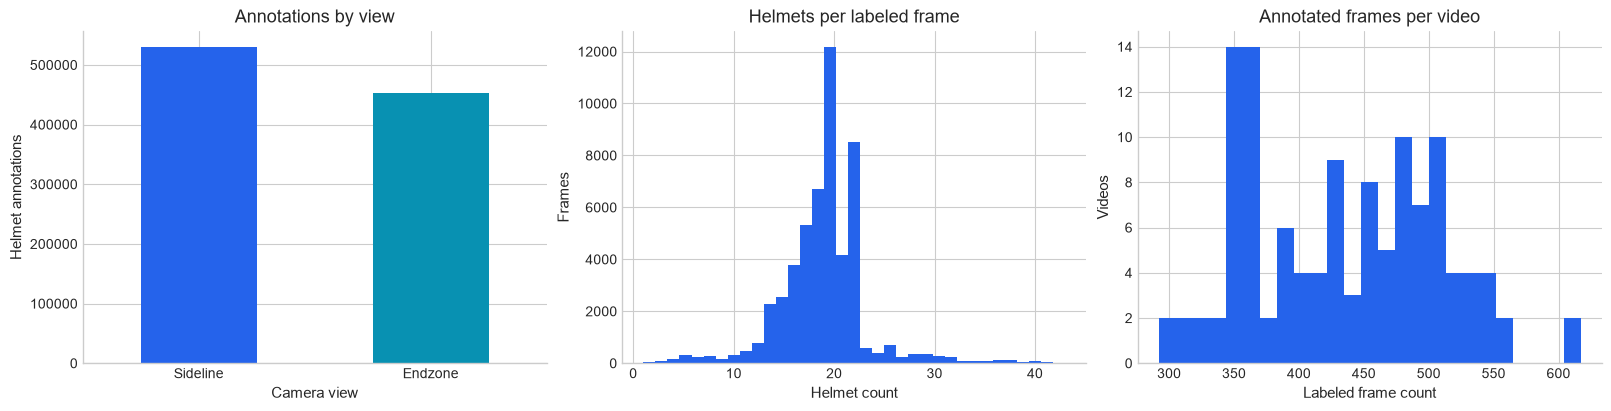

In [112]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), layout="constrained")
train_labels.view.value_counts().plot.bar(ax=axes[0], color=[BLUE, "#0891b2"], rot=0)
axes[0].set(title="Annotations by view", xlabel="Camera view", ylabel="Helmet annotations")
axes[1].hist(frame_counts, bins=35, color=BLUE)
axes[1].set(title="Helmets per labeled frame", xlabel="Helmet count", ylabel="Frames")
axes[2].hist(frames_per_video, bins=25, color=BLUE)
axes[2].set(title="Annotated frames per video", xlabel="Labeled frame count", ylabel="Videos")
plt.show()

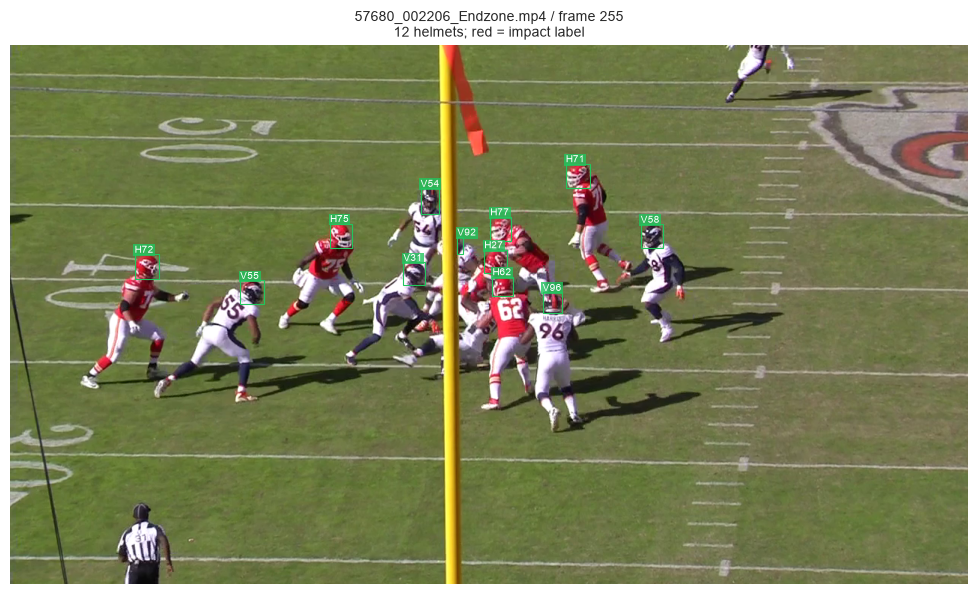

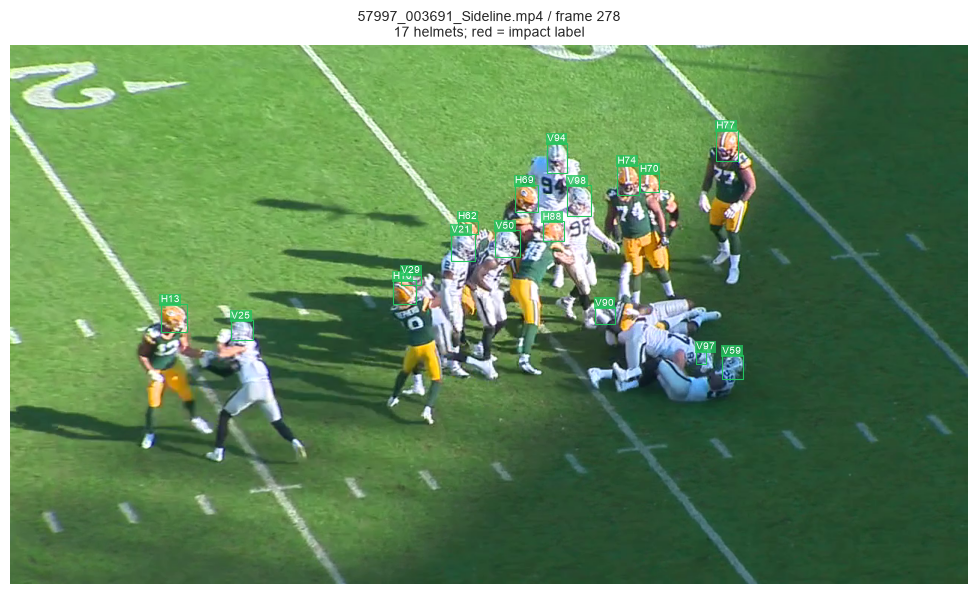

In [114]:
def show_video_frame(video_name, frame_number, show_boxes=True):
    """Display a CSV-numbered frame with player IDs; impacts are red."""
    shown = plot_video_frame(video_name, frame_number, train_labels, video_index, show_boxes)
    plt.show()
    return shown

available_videos = set(video_meta.loc[video_meta.status.eq("available"), "video"])
valid_frame_rows = train_labels.loc[train_labels.video.isin(available_videos) & train_labels.frame.ge(1)]
video_examples = valid_frame_rows.groupby("view", group_keys=False).sample(
    frac=1, random_state=SEED).drop_duplicates("view").head(3)
for row in video_examples.itertuples():
    show_video_frame(row.video, int(row.frame))
if video_examples.empty:
    display(Markdown("**No available annotated videos.** Frame visualizations are skipped."))

## 7. Impact Label Analysis
Verify the raw indicator before constructing background counts. Blank indicators are unmarked rows; absent metadata on those rows is expected. Other indicator values are flagged, not assigned to a class.

The [competition documentation](https://www.kaggle.com/c/nfl-impact-detection/data) defines its definitive, visible subset using **impact = 1, confidence > 1, visibility > 0**. This filter does not change the raw positive-row count.

**Rows are not physical events.** A collision can produce annotations across consecutive frames, two involved players, and both views. No unique-event count is inferred here.

With many more background than positive rows, accuracy can hide missed impacts. Precision measures how often predicted impacts are correct; recall measures how many labeled impacts are recovered; F1 balances the two. Future evaluation must also account for temporal and spatial matching.


In [ ]:
table(train_labels.impact.value_counts(dropna=False).rename_axis("Raw impact value").to_frame("Rows"),
      "Raw indicator values (NaN represents blank CSV fields)")
metrics({
    "Positive rows": len(positive),
    "Explicit negative rows": int(explicit_negative_mask.sum()),
    "Unmarked/background rows": int(blank_mask.sum()),
    "Positive fraction (%)": impact_pct,
    "Videos with positive labels": positive.video.nunique(),
    "Plays with positive labels": len(positive[play_keys].drop_duplicates()),
}, "Impact annotation coverage")
view_impact = train_labels.assign(positive=positive_mask).groupby("view").positive.agg(["sum", "count"])
view_impact.columns = ["Positive rows", "All annotations"]
view_impact["Positive %"] = view_impact["Positive rows"] / view_impact["All annotations"] * 100
table(view_impact, "Positive frequency by view")
impact_by_video = positive.groupby("video").size().reindex(sorted(train_labels.video.unique()), fill_value=0)
table(impact_by_video.rename("Positive rows").reset_index(), "Impact-positive counts per video, including zeroes")
fig, axes = plt.subplots(2, 2, figsize=(14, 9), layout="constrained")
class_counts = pd.Series({"Impact-positive": len(positive), "Background (blank/0)": background_count,
                         "Unexpected": int(unexpected_impact_mask.sum())})
class_counts.plot.bar(ax=axes[0, 0], color=[RED, BLUE, "#f59e0b"], rot=15)
axes[0, 0].set(title="Indicator distribution", ylabel="Annotation rows", xlabel="")
for i, count in enumerate(class_counts):
    axes[0, 0].text(i, count, f"{count:,}", ha="center", va="bottom")
view_impact["Positive %"].plot.bar(ax=axes[0, 1], color=RED, rot=0)
axes[0, 1].set(title="Impact-positive fraction by view", ylabel="Positive annotations (%)", xlabel="Camera view")
axes[1, 0].hist(impact_by_video, bins=30, color=RED)
axes[1, 0].set(title="Positive rows per video", xlabel="Positive annotation rows", ylabel="Videos")
for view, group in positive.groupby("view"):
    counts = group.groupby("frame").size()
    axes[1, 1].plot(counts.index, counts, label=view, alpha=0.8)
axes[1, 1].set(title="Positive labels over frame number (all videos)", xlabel="CSV frame number", ylabel="Positive rows")
if not positive.empty:
    axes[1, 1].legend()
plt.show()
for column in ["impactType", "confidence", "visibility"]:
    if column in train_labels:
        table(pd.concat({
            "Positive rows": positive[column].value_counts(dropna=False),
            "Background rows": train_labels.loc[blank_mask | explicit_negative_mask, column].value_counts(dropna=False)
        }, axis=1).fillna(0), f"{column}: compare labeled impacts with background")
        counts = positive[column].value_counts(dropna=False)
        if len(counts):
            fig, ax = plt.subplots(figsize=(9, 3))
            counts.rename(index=lambda value: "Missing" if pd.isna(value) else str(value)).plot.bar(ax=ax, color=RED, rot=25)
            ax.set(title=f"{column} among impact-positive rows", xlabel=column, ylabel="Positive rows")
            plt.show()
confidence = pd.to_numeric(train_labels.get("confidence", pd.Series(np.nan, index=train_labels.index)), errors="coerce")
visibility = pd.to_numeric(train_labels.get("visibility", pd.Series(np.nan, index=train_labels.index)), errors="coerce")
confirmed_mask = positive_mask & confidence.gt(1) & visibility.gt(0)
confirmed = train_labels.loc[confirmed_mask]
metrics({"Definitive and visible positive rows": len(confirmed),
         "Positive rows outside that subset": len(positive) - len(confirmed)})


## 8. Visualize Real Impacts
The examples below are selected from **actual positive labels**, preferring definitive, visible annotations. Each comes from a different video to reduce repeated examples of the same sequence; this is not event deduplication.

The temporal grid keeps a fixed context crop from the center box and draws every annotated helmet that falls into view. The nine frames are consecutive: four before, center, four after. Red boxes always follow the CSV for that frame, so neighboring frames need not have a red box. The selected player ID and center annotation are explicit.

Such clips could later capture motion, contact, and trajectory changes for a temporal classifier. This notebook only inspects them.


In [ ]:
candidate_impacts = confirmed.loc[confirmed.video.isin(available_videos) & confirmed.frame.ge(1)].copy()
if candidate_impacts.empty:
    candidate_impacts = positive.loc[positive.video.isin(available_videos) & positive.frame.ge(1)].copy()
    if not candidate_impacts.empty:
        display(Markdown("**No definitive/visible examples available; showing raw positive labels with their metadata.**"))
impact_examples = candidate_impacts.sample(frac=1, random_state=SEED).drop_duplicates("video").head(5)
metadata_columns = [c for c in ["video", "frame", "label", "impact", "impactType", "confidence", "visibility"]
                    if c in impact_examples]
table(impact_examples[metadata_columns], "Selected positive annotation rows")
for row in impact_examples.itertuples():
    display(Markdown(f"**Player {row.label} · {row.video} · annotated impact frame {int(row.frame)}**"))
    show_video_frame(row.video, int(row.frame))

sequence_row = None
metadata_by_video = video_meta.set_index("video")
for row in candidate_impacts.sample(frac=1, random_state=SEED).itertuples():
    if row.frame >= 5 and row.frame + 4 <= metadata_by_video.loc[row.video, "frame_count"]:
        sequence_row = row
        break
if sequence_row is not None:
    table(pd.DataFrame([sequence_row._asdict()])[metadata_columns], "Temporal center annotation")
    impact_sequence(sequence_row, train_labels, video_index)
    plt.show()
    fps = metadata_by_video.loc[sequence_row.video, "fps"]
    display(Markdown(f"Eight frame intervals span **{8 / fps:.3f} s**, using measured FPS **{fps:.3f}**. "
                     "This is local video timing only; no tracking synchronization is attempted."))
else:
    display(Markdown("**No available positive frame with four valid neighbors on both sides.** "
                     "The sequence helper remains available when media is supplied."))


## 9. Player Tracking Data
Timestamps are parsed in UTC and sorted within **game, play, player** before differences are calculated. The first observation in each group has no interval; duplicate timestamps have zero intervals and remain quality findings.

According to the [dataset reference](https://www.kaggle.com/c/nfl-impact-detection/data), x/y are field coordinates in yards, speed is yards/s, acceleration yards/s², and distance is the displacement from the prior observation. Orientation and movement direction are degrees. These coordinates are not pixels. We inspect timing empirically and do not synchronize tracking with video.


In [ ]:
metrics({
    "Unparseable timestamps": int(tracking_time.timestamp.isna().sum()),
    "Zero intervals": int(dt.eq(0).sum()),
    "Negative intervals after sorting": int(dt.lt(0).sum()),
    "Median positive interval (s)": median_dt,
    "Estimated rate (Hz)": 1 / median_dt if pd.notna(median_dt) and median_dt > 0 else np.nan,
    "Positive intervals within 0.09–0.11 s (%)": 100 * positive_dt.between(0.09, 0.11).mean(),
}, "Sampling interval audit")
table(positive_dt.describe(percentiles=[.01, .05, .5, .95, .99]).to_frame("Interval (s)"))
table(tracking[["s", "a", "dis", "x", "y", "o", "dir"]].describe().T, "Tracking kinematics")
fig, axes = plt.subplots(2, 3, figsize=(16, 8), layout="constrained")
for ax, column, label in zip(axes.flat[:2], ["s", "a"], ["Speed (yards/s)", "Acceleration (yards/s²)"]):
    ax.hist(tracking[column].dropna(), bins=60, color=BLUE)
    ax.set(title=label.split(" (")[0] + " distribution", xlabel=label, ylabel="Observations")
motion_sample = tracking.sample(min(15000, len(tracking)), random_state=SEED)
axes[0, 2].scatter(motion_sample.s, motion_sample.a, s=4, alpha=.15, color=BLUE)
axes[0, 2].set(title="Speed vs. acceleration (seeded sample)", xlabel="Speed (yards/s)", ylabel="Acceleration (yards/s²)")
for ax, column, label in zip(axes[1], ["dis", "o", "dir"],
                            ["Distance since prior sample (yards)", "Orientation (degrees)", "Movement direction (degrees)"]):
    ax.hist(tracking[column].dropna(), bins=60, color="#0891b2")
    ax.set(title=column, xlabel=label, ylabel="Observations")
plt.show()
fig, ax = plt.subplots(figsize=(10, 3))
ax.hist(positive_dt, bins=60, color=BLUE)
ax.axvline(.1, color=RED, linestyle="--", label="0.1 s = 10 Hz")
ax.set(title="Measured within-player timestamp differences", xlabel="Interval (s)", ylabel="Intervals")
ax.legend()
plt.show()

# Choose a seeded player/play with enough observations and a nonempty timestamp series.
eligible_players = tracking_time.loc[tracking_time.timestamp.notna()].groupby(player_keys).size()
eligible_players = eligible_players.loc[eligible_players.ge(10)]
if len(eligible_players):
    selected_player = eligible_players.sample(1, random_state=SEED).index[0]
    selector = np.ones(len(tracking_time), dtype=bool)
    for column, value in zip(player_keys, selected_player):
        selector &= tracking_time[column].eq(value).to_numpy()
    player_trace = tracking_time.loc[selector & tracking_time.timestamp.notna().to_numpy()].copy()
    player_trace["elapsed_s"] = (player_trace.timestamp - player_trace.timestamp.min()).dt.total_seconds()
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout="constrained")
    points = axes[0].scatter(player_trace.x, player_trace.y, c=player_trace.elapsed_s, cmap="viridis", s=12)
    axes[0].plot(player_trace.x, player_trace.y, alpha=.45, color=BLUE)
    axes[0].set(title=f"Player path: game/play/player {selected_player}", xlabel="Field x (yards)", ylabel="Field y (yards)")
    axes[0].set_aspect("equal", adjustable="datalim")
    fig.colorbar(points, ax=axes[0], label="Elapsed time (s)")
    axes[1].plot(player_trace.elapsed_s, player_trace.s, color=BLUE)
    axes[1].set(title="Speed over time", xlabel="Elapsed time (s)", ylabel="Speed (yards/s)")
    plt.show()
else:
    display(Markdown("No player/play has ten timestamped tracking observations."))
